# Búsquedas de *A Minecraft Movie* y *Chicken Jockey*

**Pregunta:** ¿la gente buscó más *Chicken Jockey* cuando buscó más la película? Miramos el primer semestre de 2025.

**De dónde salen los datos:** Google Trends, en todo el mundo, con un dato por semana.

**Qué tener en cuenta:** Google Trends no da cantidad de búsquedas, da números de 0 a 100. El 100 es el día (o semana) con más búsquedas de cada tema. Como los datos son por semana, no podemos ver qué pasó solo el 10 y 11 de abril. Y con 18 semanas, esto sirve para describir lo que pasó, no para decir por qué pasó.

## 1. Preparación

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Donde esta el archivo de datos
RUTA_CSV = "../data/raw/tendencias_mundial_semanal_2025-01-01_2026-11-17.csv"

# Que periodo miramos (ano-mes-dia)
INICIO = "2025-03-01"
FIN = "2025-06-30"

# La semana que incluye el estreno (4 de abril de 2025)
SEMANA_ESTRENO = "2025-03-30"

## 2. Abrir y revisar los datos

In [19]:
raw = pd.read_csv(RUTA_CSV)
print("Filas en el archivo:", len(raw))
print("Nombres de las columnas:", list(raw.columns))
raw.head()

Filas en el archivo: 27
Nombres de las columnas: ['Time', 'Una película de Minecraft', 'Chicken Jockey']


,Time,Una película de Minecraft,Chicken Jockey
0,2024-12-29,2,0
1,2025-01-05,2,0
2,2025-01-12,2,0
3,2025-01-19,2,0
4,2025-01-26,2,0


In [20]:
# Revisar que no haya datos vacios ni semanas repetidas
print("Datos vacíos:", raw.isnull().sum().sum())
print("Semanas repetidas:", raw["Time"].duplicated().sum())

Datos vacíos: 0
Semanas repetidas: 0


In [21]:
# Ordenar la tabla con nombres cortos y la fecha como titulo de cada fila
df = pd.DataFrame(
    {
        "Minecraft": raw["Una película de Minecraft"].values,
        "Chicken Jockey": raw["Chicken Jockey"].values,
    },
    index=raw["Time"].values,
)

# Quedarnos solo con el periodo que elegimos
df = df[(df.index >= INICIO) & (df.index <= FIN)]

print(f"Semanas que vamos a mirar: {len(df)}")
print(f"Desde {df.index[0]} hasta {df.index[-1]}")
df.head()

Semanas que vamos a mirar: 18
Desde 2025-03-02 hasta 2025-06-29


,Minecraft,Chicken Jockey
2025-03-02,6,0
2025-03-09,6,0
2025-03-16,9,0
2025-03-23,18,0
2025-03-30,91,2


## 3. Números generales

In [22]:
df.describe().round(1)

,Minecraft,Chicken Jockey
count,18.0,18.0
mean,25.2,2.4
std,29.0,3.1
min,6.0,0.0
25%,8.2,1.0
50%,14.0,1.0
75%,21.8,2.0
max,100.0,11.0


Cada tema tiene su propio 100, que es su semana con más búsquedas. Por eso no podemos decir que una búsqueda fue más grande que la otra en cantidad. Solo sirve para ver cómo subió y bajó cada una.

## 4. Gráfico de las búsquedas

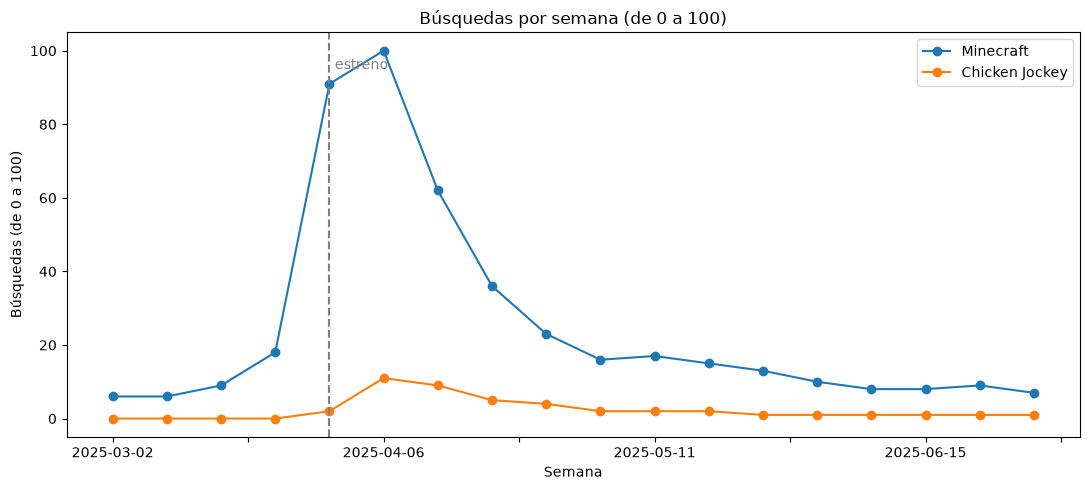

In [23]:
ax = df.plot(figsize=(11, 5), marker="o",
             title="Búsquedas por semana (de 0 a 100)")

ax.set_xlabel("Semana")
ax.set_ylabel("Búsquedas (de 0 a 100)")

# Linea gris en la semana del estreno
posicion_estreno = list(df.index).index(SEMANA_ESTRENO)
ax.axvline(posicion_estreno, color="gray", linestyle="--")
ax.text(posicion_estreno + 0.1, 95, "estreno", color="gray")

plt.tight_layout()
plt.show()

## 5. Cuándo fue el pico y cuánto tardó en bajar

In [24]:
pico_mc = df["Minecraft"].max()
semana_pico_mc = df[df["Minecraft"] == pico_mc].index[0]

pico_cj = df["Chicken Jockey"].max()
semana_pico_cj = df[df["Chicken Jockey"] == pico_cj].index[0]

print(f"A Minecraft Movie: su punto más alto fue {pico_mc} en la semana del {semana_pico_mc}")
print(f"Chicken Jockey: su punto más alto fue {pico_cj} en la semana del {semana_pico_cj}")

A Minecraft Movie: su punto más alto fue 100 en la semana del 2025-04-06
Chicken Jockey: su punto más alto fue 11 en la semana del 2025-04-06


In [25]:
# Buscar cuando la pelicula bajo a la mitad de su punto mas alto
semanas = list(df.index)
valores_mc = list(df["Minecraft"])
i_pico = semanas.index(semana_pico_mc)

i_mitad = None
for i in range(i_pico, len(semanas)):
    if valores_mc[i] <= pico_mc / 2:
        i_mitad = i
        break

if i_mitad is not None:
    print(f"La película bajó a la mitad en la semana del {semanas[i_mitad]}, "
          f"{i_mitad - i_pico} semanas después de su punto más alto.")
else:
    print("La película no bajó a la mitad dentro de este período.")

La película bajó a la mitad en la semana del 2025-04-20, 2 semanas después de su punto más alto.


Después de su punto más alto, las búsquedas de la película bajaron de forma seguida. *Chicken Jockey* llegó a su punto más alto en la misma semana que la película, pero mucho más bajo.

## 6. Comparar los dos temas

In [26]:
# Cada tema como porcentaje de su propio punto mas alto
porcentaje_del_pico = (df / df.max() * 100).round(1)
porcentaje_del_pico

,Minecraft,Chicken Jockey
2025-03-02,6.0,0.0
2025-03-09,6.0,0.0
2025-03-16,9.0,0.0
2025-03-23,18.0,0.0
2025-03-30,91.0,18.2
2025-04-06,100.0,100.0
2025-04-13,62.0,81.8
2025-04-20,36.0,45.5
2025-04-27,23.0,36.4
2025-05-04,16.0,18.2


In [27]:
semanas_con_busquedas = (df["Chicken Jockey"] > 0).sum()
print(f"Semanas con alguna búsqueda de Chicken Jockey: {semanas_con_busquedas} de {len(df)}")

Semanas con alguna búsqueda de Chicken Jockey: 14 de 18


## 7. ¿Las dos curvas suben y bajan juntas?

In [28]:
# Misma semana
parecido = df["Minecraft"].corr(df["Chicken Jockey"])
print(f"Qué tan juntas suben y bajan (misma semana): {parecido:.2f}")

Qué tan juntas suben y bajan (misma semana): 0.77


In [29]:
# Probar con 1 o 2 semanas de diferencia
# Un numero positivo significa: Chicken Jockey sube y baja unas semanas despues de la pelicula
x = df["Minecraft"].values
y = df["Chicken Jockey"].values

filas = []
for k in range(-2, 3):
    if k >= 0:
        parecido_k = np.corrcoef(x[:len(x) - k], y[k:])[0, 1]
    else:
        parecido_k = np.corrcoef(x[-k:], y[:len(y) + k])[0, 1]
    filas.append((k, round(parecido_k, 2)))

print("Semanas de diferencia | Qué tan juntas van")
for k, valor in filas:
    print(f"{k:>21} | {valor:>18}")

Semanas de diferencia | Qué tan juntas van
                   -2 |               -0.1
                   -1 |               0.28
                    0 |               0.77
                    1 |               0.97
                    2 |               0.58


Cuando las dos curvas se comparan en la misma semana, se parecen bastante. Pero el resultado más alto aparece cuando *Chicken Jockey* se mira **una semana después** de la película. Eso parece indicar que el meme sube y baja un poco después de la película.

**Ojo:** son solo 18 semanas, y las dos curvas son muy suaves. Lo que vemos puede deberse a que ambas tienen la misma forma y no a una relación real. Por eso esto es una pista para revisar con datos por día, no una conclusión.

## 8. Qué podemos decir

**Lo que sí podemos decir:**

- La película tuvo su punto más alto la semana después del estreno y después bajó de forma seguida.
- *Chicken Jockey* casi no se buscó durante todo el período. Su punto más alto coincide con la semana más fuerte de la película.
- Las dos curvas subieron y bajaron parecido, pero con tan pocas semanas no podemos saber si hay una relación real.

**Lo que falta:**

- Datos por día, para ver qué pasó el 10 y 11 de abril.
- Cuánta plata hizo la película por día en cines, para comparar con las búsquedas.
- Datos de más meses, para comparar con otras películas de 2025.